In [1]:
# Here we want to set up a reference signal and an input signal which on interfering produce three intensity distributions - one with zero phase difference at the centre and the other two on either sides.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.colors import LogNorm
from matplotlib import cm
import scipy.ndimage
from scipy.ndimage import gaussian_filter

#Creating the fields

In [16]:
#Mesh
Nx = 600
Ny = 400
X = np.linspace(0, 1, num=Nx)
Y = np.linspace(0,1, num=Ny)
xv, yv = np.meshgrid(X, Y)

Text(0.5, 1.0, 'Absolute value of the signal')

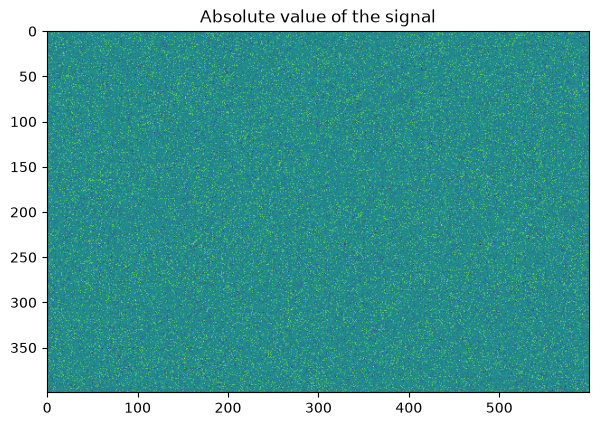

In [39]:
#Complex image to reconstruct
grainSize = 20;
temp  = np.random.rand(Ny,Nx)-.5+np.random.rand(Ny,Nx)*1j-0.5j
image_sig = scipy.ndimage.gaussian_filter(temp.real, grainSize/2)+1j*scipy.ndimage.gaussian_filter(temp.imag, grainSize/2)
image_sig = image_sig/np.abs(image_sig)
plt.figure(figsize = (7,10))
plt.imshow(abs(image_sig))
plt.title('Absolute value of the signal')

Reference Image Construction which will be tilted by an angle theta wrt the complex field

Text(0.5, 1.0, 'Absolute value of the reference')

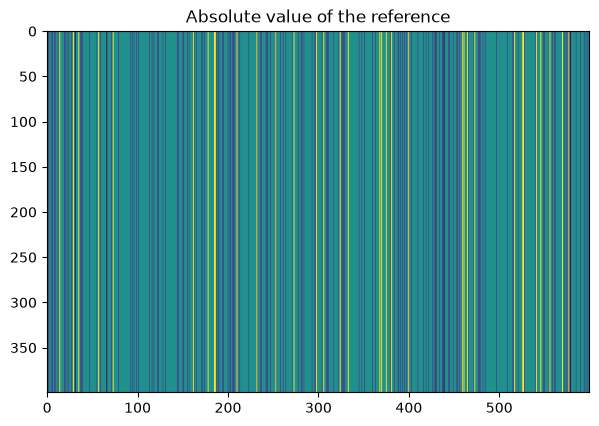

In [38]:

kx = 400
image_ref = np.exp(1j*xv*kx)
plt.figure(figsize = (7,10))
plt.imshow(abs(image_ref))
plt.title('Absolute value of the reference')

In [45]:
I = np.abs(image_ref+image_sig)**2;

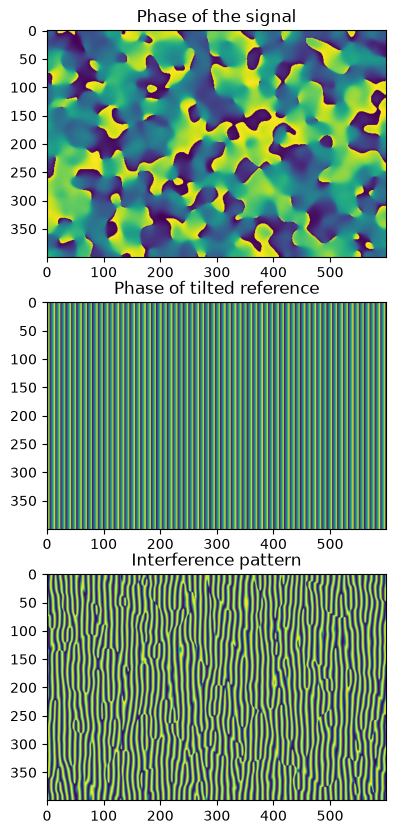

In [46]:
plt.figure(figsize = (7,10))
plt.subplot(311)
plt.imshow(np.angle(image_sig))
plt.title('Phase of the signal')
plt.subplot(312)
plt.imshow(np.angle(image_ref))
plt.title('Phase of tilted reference')
plt.subplot(313)
plt.imshow(I)
plt.title('Interference pattern')
plt.show()

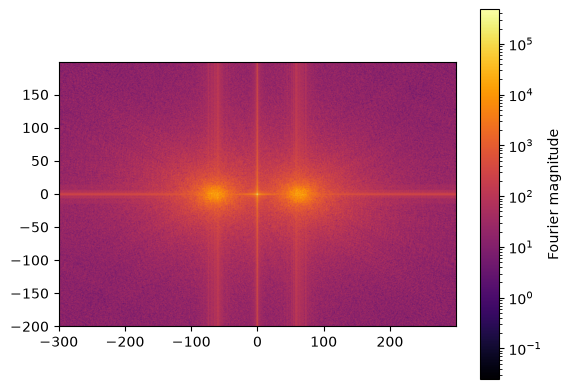

In [51]:
from matplotlib.colors import LogNorm

plt.figure()

magnitude = np.abs(Fh)

plt.imshow(
    magnitude + 1e-10,
    extent=[
        -0.5 * Nx,
        0.5 * Nx - 1,
        -0.5 * Ny,
        0.5 * Ny - 1
    ],
    
    origin='lower',
    cmap='inferno',
    norm=LogNorm()
)

plt.colorbar(label='Fourier magnitude')
plt.show()